# Part 3

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.figure import Figure

## Question 2

In [2]:
def generate_data(n_samples=500, seed=0, mean=None, covariance=None):
    """Draw random points from a 2D Gaussian/normal distribution.

    Returns an array with one row per sample and one column per dimension.

    Defaults: mean=[2, -1], covariance=[[3, 1.2], [1.2, 1]].
    """
    if mean is None:
        mean = [2.0, -1.0]
    if covariance is None:
        covariance = [[3.0, 1.2],
                      [1.2, 1.0]]

    ## instantiate random number generator
    rng = np.random.default_rng(seed)
    
    ## Draw random samples from a multivariate normal distribution.
    return rng.multivariate_normal(mean, covariance, size=n_samples, check_valid="raise")

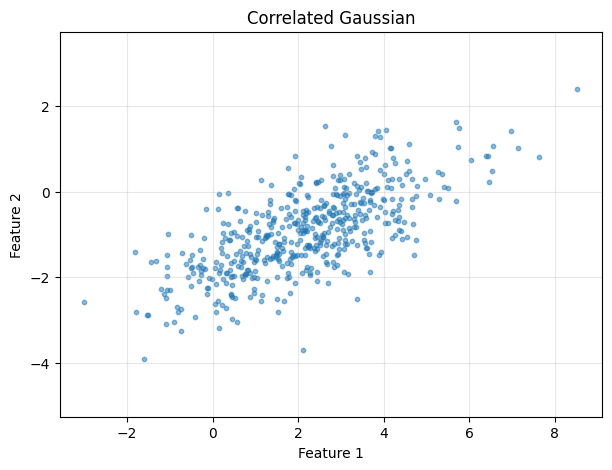

In [3]:
X = generate_data()

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], s=10, alpha=0.5)

# Equal axis scales, so the cloud's shape and tilt reflect the real covariance
plt.axis("equal")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Correlated Gaussian")
plt.grid(True, alpha=0.3)
plt.show()

**Explanation**
The correlation is structured because a covariance matrix is used. If we set the off-diagonal elements to 0, then the two distributions would look normal, but unrelated. As it was called, the two distributions have covariances of 1.2 with variances of 3 and 1.

## Question 3

### Functions

In [4]:
def pca(X: np.ndarray, n_components: int | None = None) -> dict[str, np.ndarray]:

    """Run PCA on X, where rows are samples and columns are features.

    Keeps the top `n_components` principal components (all by default).
    Returns a dict of the results from each step. X is not modified.
    """

    # Step 1: Center the data
    mean = np.mean(X, axis=0)
    centered = X - mean

    # Step 2: Compute sample covariance (divide by n-1)
    n = X.shape[0]
    covariance = (centered.T @ centered) / (n - 1)

    # Step 3: Eigenvalues and eigenvectors
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)

    # Sort by descending eigenvalue
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    components = eigenvectors[:, order][:, :n_components]

    # Step 4: Project onto principal components
    scores = centered @ components

    return {
        "mean": mean,
        "centered": centered,
        "covariance": covariance,
        "eigenvalues": eigenvalues,
        "components": components,
        "scores": scores
    }


def explained_variance(eigenvalues: np.ndarray) -> np.ndarray:
    """Return fraction of variance explained by each component."""

    total = np.sum(eigenvalues)
    return eigenvalues / total


def make_plots(X: np.ndarray, result: dict[str, np.ndarray]) -> Figure:
    """Plot data, principal directions, and explained variance."""

    mean = result["mean"]
    components = result["components"]
    eigenvalues = result["eigenvalues"]
    fractions = explained_variance(eigenvalues)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Plot 1: Original data and principal directions
    ax = axes[0]
    ax.scatter(X[:, 0], X[:, 1], alpha=0.4, label="Data")

    colors = ["red", "green"]

    for i in range(2):
        direction = components[:, i]
        length = 2 * np.sqrt(max(eigenvalues[i], 0))

        ax.quiver(
            mean[0], mean[1],
            direction[0] * length,
            direction[1] * length,
            angles="xy",
            scale_units="xy",
            scale=1,
            color=colors[i],
            label=f"PC{i+1}"
        )

    ax.scatter(mean[0], mean[1], color="black",
               marker="x", s=100, label="Mean")

    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.set_title("Data with Principal Components")
    ax.set_aspect("equal", adjustable="datalim")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # Plot 2: Explained variance
    ax = axes[1]
    ax.bar(["PC1", "PC2"], fractions)
    ax.set_xlabel("Principal Component")
    ax.set_ylabel("Explained Variance Fraction")
    ax.set_title("Explained Variance by Component")
    ax.set_ylim(0, 1)

    for i, fraction in enumerate(fractions):
        ax.text(i, fraction + 0.02,
                f"{fraction:.1%}", ha="center")

    fig.tight_layout()
    return fig

### Run

Mean: [ 2.1523992  -0.93464455]

Covariance matrix:
 [[2.91615571 1.1656626 ]
 [1.1656626  0.95302538]]

Eigenvalues: [3.45848013 0.41070096]

Principal components:
 [[-0.90667478  0.42183036]
 [-0.42183036 -0.90667478]]

Explained variance: [0.89385326 0.10614674]


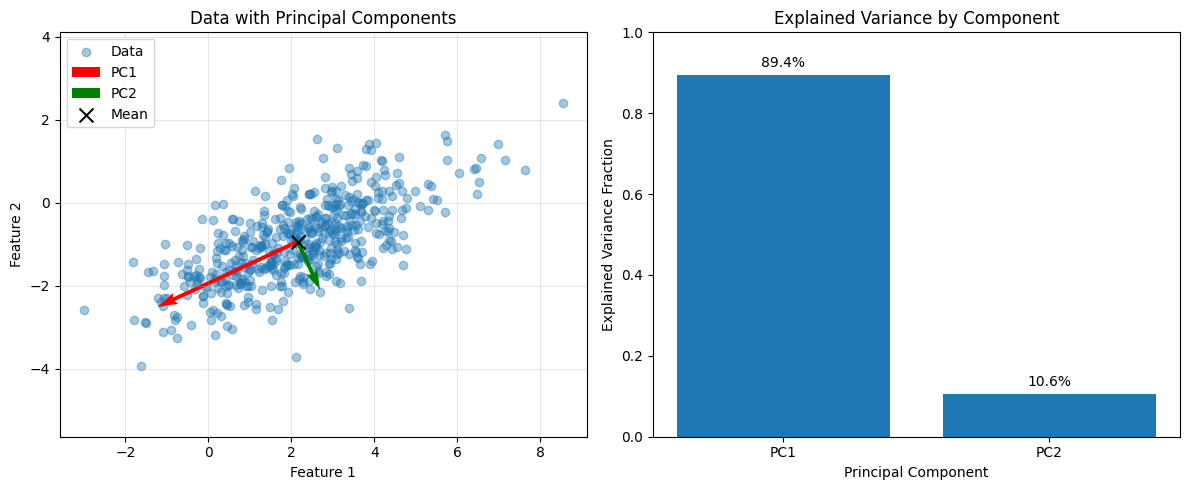

In [5]:
# Generate data from Q2
X = generate_data(n_samples=500, seed=0)

# Fit PCA
result = pca(X)

# Print results
print("Mean:", result["mean"])
print("\nCovariance matrix:\n", result["covariance"])
print("\nEigenvalues:", result["eigenvalues"])
print("\nPrincipal components:\n", result["components"])
print("\nExplained variance:",
      explained_variance(result["eigenvalues"]))

# Plot
fig = make_plots(X, result)
plt.show()


## Question 4

In [6]:

# Use PCA results from Q3
result = pca(X)

# Calculate explained variance ratios
ratios     = explained_variance(result["eigenvalues"])
cumulative = np.cumsum(ratios)

for i in range(len(ratios)):
    print(f"PC{i+1}: {ratios[i]:.2%} explained variance")
    print(f"  Cumulative: {cumulative[i]:.2%}")

# Reduce from 2D to 1D by keeping PC1
X_reduced = result["scores"][:, :1]

print("\nOriginal shape:", X.shape)
print("Reduced shape:", X_reduced.shape)
print(f"Variance retained: {ratios[0]:.2%}")
print(f"Variance lost: {1 - ratios[0]:.2%}")


PC1: 89.39% explained variance
  Cumulative: 89.39%
PC2: 10.61% explained variance
  Cumulative: 100.00%

Original shape: (500, 2)
Reduced shape: (500, 1)
Variance retained: 89.39%
Variance lost: 10.61%


As it is run right now, most of the data can be explained by the first PC. This makes sense because we set the covariance relatively high. So the two dimensions should be related.

This example (a 2 dimension, highly correlated set) makes it look like its easy to reduce dimensions. Sometimes it is not, and often we don't get nearly this good of PC loadings.

As expected, for a 2D example with 2 PCs we are explaining all of the variance. Often, however we have more dimensions and reducing is very practical/useful -- even if the PC loadings are lower. 